# 19. 상대적 변화율 Ridge: 소규모 격자의 영향 분리

기존 18번의 Y·4변수를 유지하고 전체·개통 전 5명 이상·10명 이상을 **사전 고정 민감도 분석**으로 비교한다. 최종 임계값을 선택하지 않는다.

- 전체 126개로 계산한 권역 변화율 R_s를 세 실험에서 고정한다. 소규모 격자를 제외한 뒤 R_s를 다시 계산하면 예측대상 자체가 바뀌기 때문이다.
- 기준을 통과한 학습격자로 다시 내부 LOSO를 수행해 alpha를 선택하고, 외부 검증역에서도 같은 기준을 통과한 격자만 평가한다.
- 학습역 내부에서만 결측치 대체·표준화·alpha 선택. Y 계산에만 사용하던 개통 전 승차량을 이번에는 대상 선정에도 쓰지만 X에는 넣지 않는다.
- **평가대상 변경과 재학습 효과를 구분**: 같은 평가격자에 대해 기존 전체 학습모형 OOF, 기준 적용 후 재학습 OOF, Y=0 기준을 나란히 비교한다.
- 임계값별 검증 모집단이 다르므로 20.4→11.6만으로 모형 개선을 주장하지 않는다. 같은 외부 결과로 좋은 임계값을 고르면 선택 편향이 남는다. 향후 선택 실험을 한다면 공통 평가대상·적용범위 또는 보류 비용을 먼저 정하고 학습자료 안에서만 선택해야 한다.
- 기존 OLS·18번을 변경하지 않는다. CSV·모델·그림 파일 자동 저장 없음.

In [1]:
# 프로젝트 루트(UROP) 자동 탐색 — 절대경로 없이 어느 컴퓨터에서도 동작
import sys
from pathlib import Path
UROP_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config.py').is_file() and (p / 'code').is_dir())
for _d in [UROP_ROOT, *sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir() and d.name != '__pycache__')]:
    if str(_d) not in sys.path:
        sys.path.append(str(_d))

from pathlib import Path
import importlib.util
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display
paths=[*sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir()), Path.cwd(),Path.cwd()/'analysis',Path.cwd()/'gtx_a_bus_analysis'/'analysis',Path.cwd()/'github_2026-UROP'/'gtx_a_bus_analysis'/'analysis']
ANALYSIS=next((p for p in paths if (p/'19_상대적변화율_소규모격자_민감도.py').exists()),None)
if ANALYSIS is None:raise FileNotFoundError('analysis 또는 프로젝트 폴더에서 실행하세요.')
spec=importlib.util.spec_from_file_location('sensitivity',next((UROP_ROOT / 'code').rglob('19_상대적변화율_소규모격자_민감도.py')))
experiment=importlib.util.module_from_spec(spec);spec.loader.exec_module(experiment)
fonts={f.name for f in font_manager.fontManager.ttflist}
font=next((f for f in ['AppleGothic','Apple SD Gothic Neo','NanumGothic','Malgun Gothic','Noto Sans CJK KR'] if f in fonts),None)
if font:plt.rcParams['font.family']=font
plt.rcParams.update({'axes.unicode_minus':False,'font.size':11,'figure.dpi':110})
results,coverage,overall,folds,ranks,tops,paired,totals=experiment.evaluate()
display(totals.round(3))
display(coverage.round(4))
print('0명은 없음. 5명 기준 14개, 10명 기준 24개가 적용범위에서 제외된다.')

0명은 없음. 5명 기준 14개, 10명 기준 24개가 적용범위에서 제외된다.


,n,pre,post,zero_pre,R_s
nearest_station,,,,,
대곡,37,2622.0,1016.0,0,-61.251
운정중앙,63,6491.0,1911.0,0,-70.559
킨텍스,26,8781.0,2658.0,0,-69.730


,기준,검증역,원래n,대상n,제외n,대상비율,유지된개통전승차비율,기초0명
0,0,운정중앙,63,63,0,1.0000,1.0000,0
1,0,킨텍스,26,26,0,1.0000,1.0000,0
2,0,대곡,37,37,0,1.0000,1.0000,0
3,5,운정중앙,63,56,7,0.8889,0.9969,0
4,5,킨텍스,26,26,0,1.0000,1.0000,0
5,5,대곡,37,30,7,0.8108,0.9920,0
6,10,운정중앙,63,49,14,0.7778,0.9897,0
7,10,킨텍스,26,25,1,0.9615,0.9990,0
8,10,대곡,37,28,9,0.7568,0.9863,0


## 1. 각 적용범위의 결과

같은 행의 표본에 대해 Ridge와 단순 기준을 비교한다. 서로 다른 적용범위의 MAE 감소는 모형 개선과 같지 않다. 기준 0은 기초 0명 격자를 포함한다는 뜻이 아니라, Y가 정의되는 전체 표본이라는 뜻이다.

In [2]:
display(overall.round(4))
display(folds[folds['모형'].isin(['Ridge','0 기준'])].round(4))
display(ranks.round(4))
display(tops.round(4))

,기준,모형,MAE(%p),RMSE(%p),R2
0,0,Ridge,20.4013,40.2313,0.0793
1,0,0 기준,19.1670,43.2184,-0.0625
2,0,학습평균 기준,21.5979,42.1003,-0.0083
3,0,학습중앙값 기준,19.1668,43.1076,-0.0571
4,5,Ridge,13.9587,22.0806,-0.0668
5,5,0 기준,13.4762,21.7639,-0.0364
6,5,학습평균 기준,14.1895,21.9288,-0.0521
7,5,학습중앙값 기준,13.4872,21.7691,-0.0369
8,10,Ridge,11.5529,17.0055,-0.0238
9,10,0 기준,11.3549,16.8875,-0.0097


,기준,검증역,모형,n,alpha,내부역평균MAE,MAE(%p),RMSE(%p),R2
0,0,운정중앙,Ridge,63,100.0000,19.2205,20.7388,31.7723,0.0913
1,0,운정중앙,0 기준,63,NaN,NaN,19.8488,35.6736,-0.1456
4,0,킨텍스,Ridge,26,100.0000,23.8271,13.0452,18.7553,0.0450
5,0,킨텍스,0 기준,26,NaN,NaN,11.1310,19.4516,-0.0272
8,0,대곡,Ridge,37,31.6228,16.7290,24.9957,59.5469,0.0640
9,0,대곡,0 기준,37,NaN,NaN,23.6531,62.6737,-0.0369
12,5,운정중앙,Ridge,56,1000.0000,12.0451,15.3179,25.1748,-0.0751
13,5,운정중앙,0 기준,56,NaN,NaN,15.2860,25.3890,-0.0935
16,5,킨텍스,Ridge,26,31.6228,14.5275,11.6269,19.6957,-0.0532
17,5,킨텍스,0 기준,26,NaN,NaN,11.1310,19.4516,-0.0272


,기준,검증역,n,Y>0 격자수,Y>0 비율,ROC_AUC(Y>0),Spearman(연속Y)
0,0,운정중앙,63,34,0.5397,0.6744,0.2908
1,0,킨텍스,26,14,0.5385,0.5952,0.2219
2,0,대곡,37,18,0.4865,0.5117,0.0591
3,5,운정중앙,56,28,0.5000,0.5128,-0.0028
4,5,킨텍스,26,14,0.5385,0.5536,0.0913
5,5,대곡,30,14,0.4667,0.4732,-0.0438
6,10,운정중앙,49,22,0.4490,0.6178,0.1335
7,10,킨텍스,25,13,0.5200,0.5769,0.1638
8,10,대곡,28,13,0.4643,0.5282,0.0818


,기준,검증역,상위비율,K,Y>0 격자수,Precision,Lift,실제Y중앙값,실제Y평균
0,0,운정중앙,0.1,7,5,0.7143,1.3235,3.8926,11.6135
1,0,운정중앙,0.2,13,10,0.7692,1.4253,19.3964,24.1815
2,0,운정중앙,0.3,19,15,0.7895,1.4628,20.5592,31.9002
3,0,킨텍스,0.1,3,3,1.0000,1.8571,3.0634,27.6940
4,0,킨텍스,0.2,6,4,0.6667,1.2381,1.9140,9.8776
5,0,킨텍스,0.3,8,5,0.6250,1.1607,1.9140,7.9089
6,0,대곡,0.1,4,2,0.5000,1.0278,5.1903,84.7832
7,0,대곡,0.2,8,5,0.6250,1.2847,8.5237,51.9206
8,0,대곡,0.3,12,6,0.5000,1.0278,-0.1444,32.5332
9,5,운정중앙,0.1,6,4,0.6667,1.3333,22.7950,20.7374


## 2. 같은 검증 격자에서 전체 학습과 제외 후 재학습 비교

아래에서 **평가대상기준=10**의 세 모형은 동일한 102개 OOF 격자·동일한 Y를 평가한다. 전체 모형을 그대로 두고 평가만 102개로 줄이는 경우와 학습도 10명 이상으로 제한한 경우를 구분한다. 5명 기준도 동일하게 112개에서 비교한다.

,평가대상기준,검증역,모형,n,MAE(%p),RMSE(%p),R2
0,0,전체,전체학습모형의같은대상예측,126,20.4013,40.2313,0.0793
1,0,전체,기준적용후재학습,126,20.4013,40.2313,0.0793
2,0,전체,Y=0 기준,126,19.1670,43.2184,-0.0625
3,0,운정중앙,전체학습모형의같은대상예측,63,20.7388,31.7723,0.0913
4,0,운정중앙,기준적용후재학습,63,20.7388,31.7723,0.0913
5,0,운정중앙,Y=0 기준,63,19.8488,35.6736,-0.1456
6,0,킨텍스,전체학습모형의같은대상예측,26,13.0452,18.7553,0.0450
7,0,킨텍스,기준적용후재학습,26,13.0452,18.7553,0.0450
8,0,킨텍스,Y=0 기준,26,11.1310,19.4516,-0.0272
9,0,대곡,전체학습모형의같은대상예측,37,24.9957,59.5469,0.0640


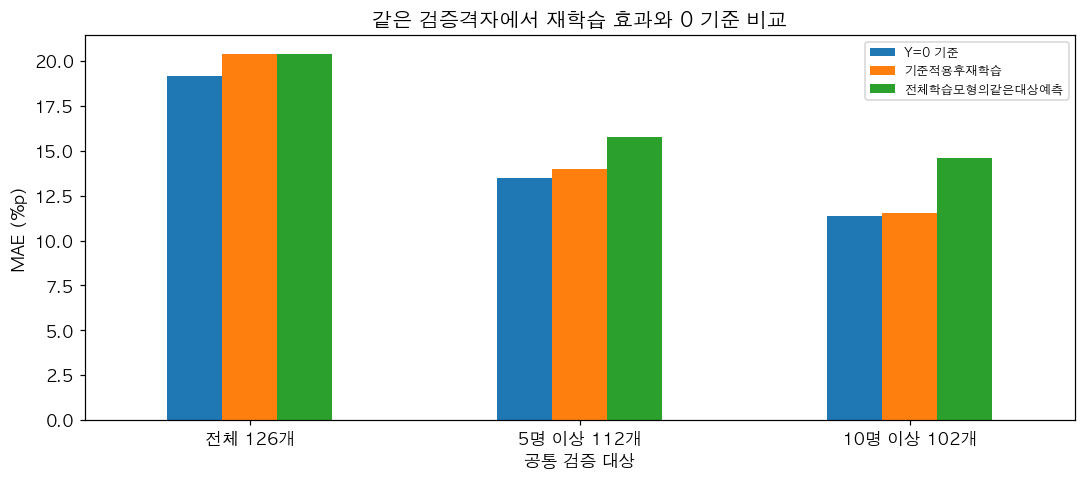

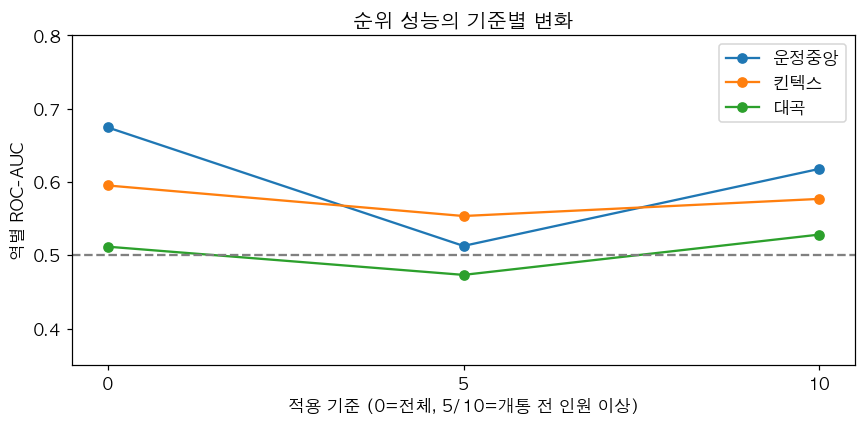

In [3]:
display(paired.round(4))
view=paired[paired['검증역']=='전체'].copy()
fig,ax=plt.subplots(figsize=(10,4.5))
view.pivot(index='평가대상기준',columns='모형',values='MAE(%p)').plot.bar(ax=ax)
ax.set_xticklabels(['전체 126개','5명 이상 112개','10명 이상 102개'],rotation=0)
ax.set(xlabel='공통 검증 대상',ylabel='MAE (%p)',title='같은 검증격자에서 재학습 효과와 0 기준 비교')
ax.legend(fontsize=8);plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(8,4))
for station,g in ranks.groupby('검증역',sort=False):
 ax.plot(g['기준'],g['ROC_AUC(Y>0)'],marker='o',label=station)
ax.axhline(.5,color='gray',ls='--');ax.set_xticks([0,5,10]);ax.set(xlabel='적용 기준 (0=전체, 5/10=개통 전 인원 이상)',ylabel='역별 ROC-AUC',title='순위 성능의 기준별 변화',ylim=(.35,.8))
ax.legend();plt.tight_layout();plt.show()

## 3. 해석과 GTX-C 적용범위

| 적용범위 | n | Ridge MAE | Y=0 MAE | Ridge RMSE | Ridge R² |
|---|---:|---:|---:|---:|---:|
| 전체 | 126 | 20.401 | 19.167 | 40.231 | 0.079 |
| 5명 이상 | 112 | 13.959 | 13.476 | 22.081 | −0.067 |
| 10명 이상 | 102 | 11.553 | 11.355 | 17.006 | −0.024 |

- 같은 112개 격자에서 전체 모형 MAE 15.773→재학습 13.959%p, 같은 102개에서 14.584→11.553%p로 줄었다. 따라서 작은 격자의 극단적 Y가 다른 격자의 학습에도 영향을 준 것으로 해석할 수 있다.
- 그러나 제외 후에도 각 범위의 Y=0 기준을 이기지 못했다. 5명 이상에서 RMSE도 0 기준보다 크고, 10명 이상도 동일하다. **소규모 격자가 유일한 문제였다고 볼 수 없다.**
- 10명 이상 순위 AUC: 운정중앙 .618, 킨텍스 .577, 대곡 .528. 권역 전반에 강하게 재현되는 순위 신호가 확인된 것은 아니다.
- 5/10 기준 중 점수가 좋은 것을 최종값으로 채택하지 않았다. 기초 0명 격자는 세 경우 모두 0개다.
- 향후 C에 어떤 기준을 채택한다면, 미달 격자는 **적용 대상 아님/별도 검토**로 표시하고 예측값 0을 넣지 않는다. C 격자수 대비 적용 비율과 기존 승차량 대비 포함 비율을 같이 보고해야 한다.
- 이번 노트북은 C에 실제 적용하지 않는다. C 기준연도·OD 범위·역 권역 정의와 공통 입력 구축이 필요하다. 제외된 저수요 지역의 서비스 필요성까지 낮다고 해석하면 안 된다.

In [4]:
# 실제 C 예측이 아니라 적용대상 표시 규칙의 예시다.
example=pd.DataFrame({'개통전승차':[0,3,7,15]})
example['5명기준']=experiment.target_status(example['개통전승차'],5)
example['10명기준']=experiment.target_status(example['개통전승차'],10)
display(example)

,개통전승차,5명기준,10명기준
0,0,기초 0명: 변화율 정의 불가,기초 0명: 변화율 정의 불가
1,3,기준 미만: 적용 대상 아님,기준 미만: 적용 대상 아님
2,7,적용 대상,기준 미만: 적용 대상 아님
3,15,적용 대상,적용 대상
